# Validation: epoch length and filtering boundary effects

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorpac import EventRelatedPac
from tensorpac.methods import erpac
from scipy.stats import skew

SFREQ = 500
N_TRIALS = 66
N_SURROGATES = 200
SEED = 42

F_THETA = 6
F_GAMMA = 50

F_PHA = [4, 8]
F_AMP = (30, 80, 5, 1)

times = np.arange(-750, 751) / SFREQ

short_mask = (times >= -0.5) & (times <= 0.5)
short_times = times[short_mask]

toi_mask = (short_times >= 0) & (short_times < 0.5)

print("Extended epoch:", len(times), "samples")
print("Short epoch:", len(short_times), "samples")
print("Analysis window:", toi_mask.sum(), "samples")

Extended epoch: 1501 samples
Short epoch: 501 samples
Analysis window: 250 samples


In [2]:
# Generate synthetic EEG data
rng = np.random.default_rng(SEED)

# Random starting phase across trials
theta_offsets = rng.uniform(
    -np.pi, np.pi, size=(N_TRIALS, 1)
)

gamma_offsets = rng.uniform(
    -np.pi, np.pi, size=(N_TRIALS, 1)
)

# Theta phase
theta_phase = (
    2 * np.pi * F_THETA * times[None, :]
    + theta_offsets
)

theta = np.sin(theta_phase)

# Gamma carrier
gamma = np.sin(
    2 * np.pi * F_GAMMA * times[None, :]
    + gamma_offsets
)

# Identical noise for both controls
noise = rng.normal(
    0, 0.5, size=theta.shape
)

# Negative control: no theta modulation
x_uncoupled = theta + gamma + noise

# Positive control: theta-modulated gamma amplitude
modulation_depth = 0.8

gamma_envelope = (
    1 + modulation_depth * np.cos(theta_phase)
)

x_coupled = (
    theta
    + gamma_envelope * gamma
    + noise
)

print(x_uncoupled.shape)
print(x_coupled.shape)

(66, 1501)
(66, 1501)


In [3]:
# Extract phase and amplitude

pac = EventRelatedPac(
    f_pha=F_PHA,
    f_amp=F_AMP,
    dcomplex="hilbert",
    cycle=(3, 6),
    verbose=False
)


def extract_phase_amplitude(x, extended=True):

    if extended:

        # Approach A: filter first, crop afterwards
        pha = pac.filter(
            SFREQ, x,
            ftype="phase",
            n_jobs=1
        )

        amp = pac.filter(
            SFREQ, x,
            ftype="amplitude",
            n_jobs=1
        )

        pha = pha[..., short_mask]
        amp = amp[..., short_mask]

    else:

        # Approach B: crop first, filter afterwards
        x_short = x[:, short_mask]

        pha = pac.filter(
            SFREQ, x_short,
            ftype="phase",
            n_jobs=1
        )

        amp = pac.filter(
            SFREQ, x_short,
            ftype="amplitude",
            n_jobs=1
        )

    return pha, amp

In [4]:
# Generate identical trial permutations
rng_sur = np.random.default_rng(SEED + 1)

permutations = np.stack([
    rng_sur.permutation(N_TRIALS)
    for _ in range(N_SURROGATES)
])

print(permutations.shape)

# Calculate observed and surrogate ERPAC
def compute_erpac(pha, amp):

    # Tensorpac's low-level ERPAC estimator
    # expects the trial axis at the end
    rho, _ = erpac(
        np.moveaxis(pha, 1, -1),
        np.moveaxis(amp, 1, -1)
    )

    return rho


def validate_erpac(pha, amp):

    # Observed ERPAC
    observed = compute_erpac(pha, amp)

    observed_mean = observed[..., toi_mask].mean()

    # Surrogate ERPAC
    surrogate_values = np.empty(N_SURROGATES)

    for i, perm in enumerate(permutations):

        amp_shuffled = amp[:, perm, :]

        surrogate = compute_erpac(
            pha, amp_shuffled
        )

        surrogate_values[i] = (
            surrogate[..., toi_mask].mean()
        )

    # Surrogate normalization
    surrogate_mean = surrogate_values.mean()

    surrogate_sd = surrogate_values.std(ddof=1)

    if surrogate_sd <= 0:
        raise ValueError("Zero surrogate variance")

    z = (
        observed_mean - surrogate_mean
    ) / surrogate_sd

    p_empirical = (
        1 + np.sum(surrogate_values >= observed_mean)
    ) / (N_SURROGATES + 1)

    return {
        "observed": observed_mean,
        "surrogate_mean": surrogate_mean,
        "surrogate_sd": surrogate_sd,
        "z": z,
        "p_empirical": p_empirical,
        "surrogate_skewness": skew(surrogate_values),
        "observed_map": observed,
        "surrogate_values": surrogate_values
    }

(200, 66)


In [6]:
# Run all four validation scenarios
results = {}

for control, x in [
    ("Uncoupled", x_uncoupled),
    ("Coupled", x_coupled)
]:

    for method, extended in [
        ("Extended", True),
        ("Short", False)
    ]:

        print(f"Running: {control}, {method}")

        pha, amp = extract_phase_amplitude(
            x,
            extended=extended
        )

        results[(control, method)] = validate_erpac(
            pha, amp
        )

print("Validation completed.")

# Summarize results
summary = pd.DataFrame([
    {
        "control": control,
        "filtering": method,
        "observed": r["observed"],
        "surrogate_mean": r["surrogate_mean"],
        "surrogate_sd": r["surrogate_sd"],
        "z": r["z"],
        "p_empirical": r["p_empirical"],
        "surrogate_skewness": r["surrogate_skewness"]
    }
    for (control, method), r in results.items()
])

print(summary.round(6).to_string(index=False))

Running: Uncoupled, Extended
Running: Uncoupled, Short
Running: Coupled, Extended
Running: Coupled, Short
Validation completed.
  control filtering  observed  surrogate_mean  surrogate_sd         z  p_empirical  surrogate_skewness
Uncoupled  Extended  0.149214        0.156374      0.010094 -0.709321     0.786070           -0.024272
Uncoupled     Short  0.143321        0.156621      0.010484 -1.268653     0.920398            0.006058
  Coupled  Extended  0.508626        0.157904      0.020759 16.894818     0.004975            0.320485
  Coupled     Short  0.498076        0.158162      0.019783 17.182296     0.004975            0.333056


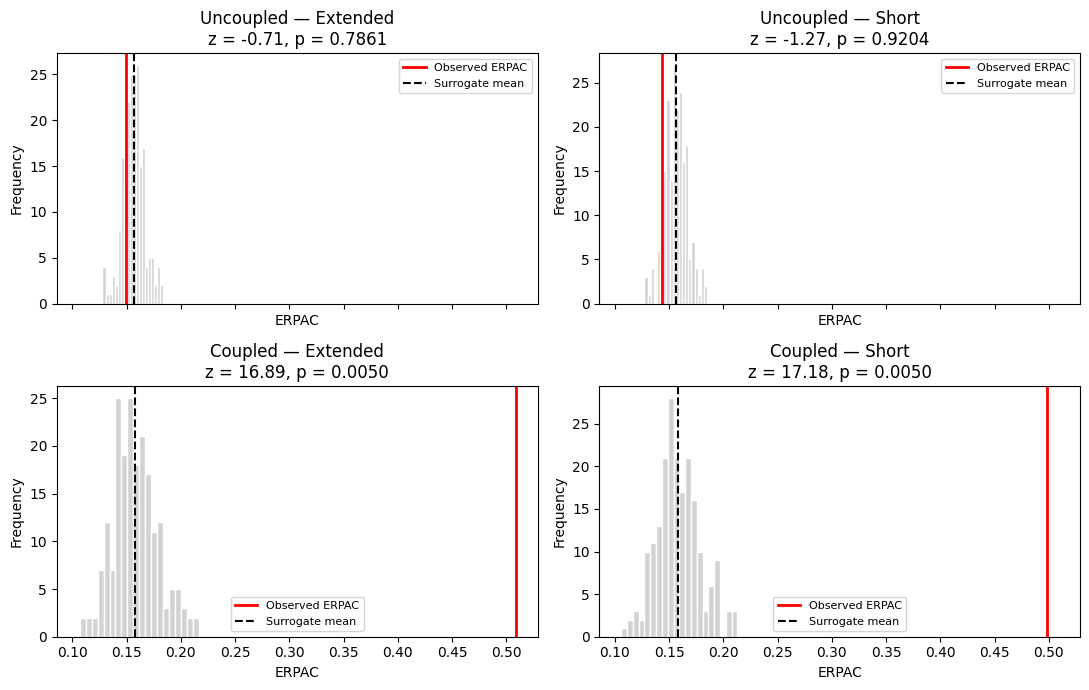

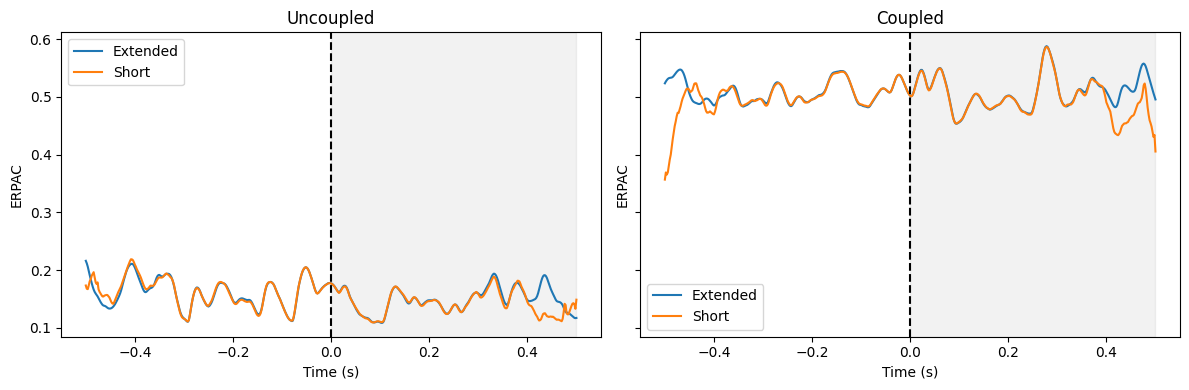

In [7]:
# Plot surrogate distributions
fig, axes = plt.subplots(
    2, 2,
    figsize=(11, 7),
    sharex=True
)

for ax, ((control, method), r) in zip(
    axes.flat, results.items()
):

    ax.hist(
        r["surrogate_values"],
        bins=20,
        color="lightgrey",
        edgecolor="white"
    )

    ax.axvline(
        r["observed"],
        color="red",
        linewidth=2,
        label="Observed ERPAC"
    )

    ax.axvline(
        r["surrogate_mean"],
        color="black",
        linestyle="--",
        label="Surrogate mean"
    )

    ax.set_title(
        f"{control} — {method}\n"
        f"z = {r['z']:.2f}, "
        f"p = {r['p_empirical']:.4f}"
    )

    ax.set_xlabel("ERPAC")
    ax.set_ylabel("Frequency")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

# Examine time-resolved boundary effects
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4),
    sharey=True
)

for ax, control in zip(
    axes, ["Uncoupled", "Coupled"]
):

    for method in ["Extended", "Short"]:

        observed_map = results[
            (control, method)
        ]["observed_map"]

        # Average over phase and amplitude frequencies
        erpac_timecourse = observed_map.mean(
            axis=(0, 1)
        )

        ax.plot(
            short_times,
            erpac_timecourse,
            label=method
        )

    ax.axvline(0, color="black", linestyle="--")
    ax.axvspan(0, 0.5, color="grey", alpha=0.1)

    ax.set_title(control)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("ERPAC")
    ax.legend()

plt.tight_layout()
plt.show()

In [8]:
# Compare ERPAC within individual time windows
# Time windows used in Study 2 LMMs
time_windows = {
    "plan": {
        "early": (0.0, 0.2),
        "middle": (0.2, 0.35),
        "late": (0.35, 0.5)
    },
    "go": {
        "early": (0.0, 0.15),
        "middle": (0.15, 0.3),
        "late": (0.3, 0.5)
    }
}

rows = []

for control in ["Uncoupled", "Coupled"]:

    extended = results[
        (control, "Extended")
    ]["observed_map"]

    short = results[
        (control, "Short")
    ]["observed_map"]

    for stage, windows in time_windows.items():

        for window, (tmin, tmax) in windows.items():

            mask = (
                (short_times >= tmin)
                & (short_times < tmax)
            )

            extended_mean = extended[..., mask].mean()
            short_mean = short[..., mask].mean()

            difference = short_mean - extended_mean

            relative_difference = (
                difference / extended_mean * 100
            )

            rows.append({
                "control": control,
                "task_stage": stage,
                "time_window": window,
                "extended_erpac": extended_mean,
                "short_erpac": short_mean,
                "difference": difference,
                "relative_difference_pct": relative_difference
            })

window_comparison = pd.DataFrame(rows)

print(
    window_comparison.round(6).to_string(index=False)
)

  control task_stage time_window  extended_erpac  short_erpac  difference  relative_difference_pct
Uncoupled       plan       early        0.143528     0.143595    0.000067                 0.046666
Uncoupled       plan      middle        0.151701     0.149441   -0.002260                -1.489587
Uncoupled       plan        late        0.154308     0.136835   -0.017474               -11.323856
Uncoupled         go       early        0.142702     0.142750    0.000048                 0.033892
Uncoupled         go      middle        0.142556     0.142343   -0.000212                -0.149049
Uncoupled         go        late        0.159092     0.144482   -0.014610                -9.183361
  Coupled       plan       early        0.501368     0.501001   -0.000366                -0.073085
  Coupled       plan      middle        0.509586     0.508800   -0.000787                -0.154355
  Coupled       plan        late        0.517342     0.483451   -0.033891                -6.551079
  Coupled 

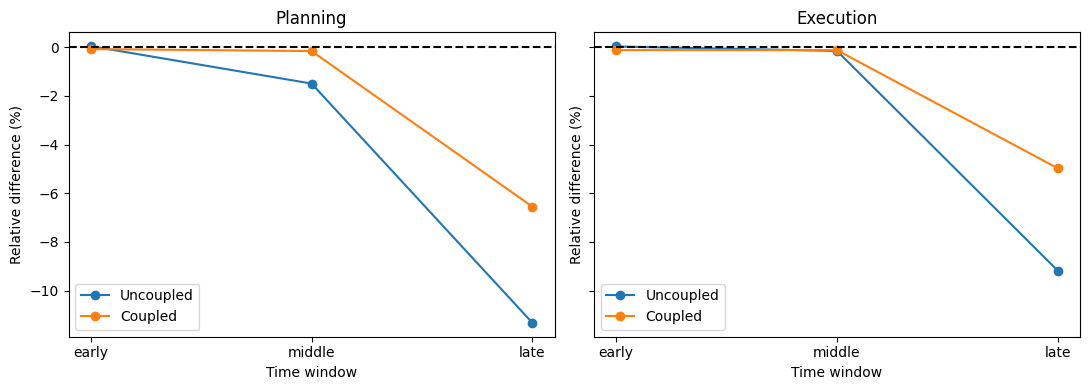

In [9]:
# Visualize the relative estimation error
fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 4),
    sharey=True
)

for ax, stage in zip(axes, ["plan", "go"]):

    for control in ["Uncoupled", "Coupled"]:

        d = window_comparison[
            (window_comparison["task_stage"] == stage)
            & (window_comparison["control"] == control)
        ]

        ax.plot(
            d["time_window"],
            d["relative_difference_pct"],
            marker="o",
            label=control
        )

    ax.axhline(
        0,
        color="black",
        linestyle="--"
    )

    ax.set_title(
        "Planning" if stage == "plan" else "Execution"
    )

    ax.set_xlabel("Time window")
    ax.set_ylabel("Relative difference (%)")
    ax.legend()

plt.tight_layout()
plt.show()

In [12]:
# Calculate window-specific surrogate statistics
window_results = []

for control, x in [
    ("Uncoupled", x_uncoupled),
    ("Coupled", x_coupled)
]:

    for method, extended in [
        ("Extended", True),
        ("Short", False)
    ]:

        print(f"Running: {control}, {method}")

        pha, amp = extract_phase_amplitude(
            x,
            extended=extended
        )

        df = validate_erpac_windows(pha, amp)

        df["control"] = control
        df["filtering"] = method

        window_results.append(df)

window_z_results = pd.concat(
    window_results,
    ignore_index=True
)

print(
    window_z_results.round(6).to_string(index=False)
)


Running: Uncoupled, Extended
Running: Uncoupled, Short
Running: Coupled, Extended
Running: Coupled, Short
task_stage time_window  observed  surrogate_mean  surrogate_sd         z  p_empirical   control filtering
      plan       early  0.143528        0.156522      0.014732 -0.882003     0.835821 Uncoupled  Extended
      plan      middle  0.151701        0.157401      0.018385 -0.310080     0.597015 Uncoupled  Extended
      plan        late  0.154308        0.155150      0.018480 -0.045526     0.487562 Uncoupled  Extended
        go       early  0.142702        0.156391      0.017552 -0.779927     0.781095 Uncoupled  Extended
        go      middle  0.142556        0.157722      0.017283 -0.877552     0.805970 Uncoupled  Extended
        go        late  0.159092        0.155350      0.015643  0.239205     0.412935 Uncoupled  Extended
      plan       early  0.143595        0.156586      0.014744 -0.881073     0.835821 Uncoupled     Short
      plan      middle  0.149441        0.1574

In [13]:
# Compare z-scores directly
z_comparison = window_z_results.pivot(
    index=["control", "task_stage", "time_window"],
    columns="filtering",
    values="z"
).reset_index()

z_comparison["z_difference"] = (
    z_comparison["Short"]
    - z_comparison["Extended"]
)

window_order = ["early", "middle", "late"]

z_comparison["time_window"] = pd.Categorical(
    z_comparison["time_window"],
    categories=window_order,
    ordered=True
)

z_comparison = z_comparison.sort_values(
    ["control", "task_stage", "time_window"]
)

print(
    z_comparison.round(4).to_string(index=False)
)

  control task_stage time_window  Extended   Short  z_difference
  Coupled         go       early   14.5398 14.5143       -0.0255
  Coupled         go      middle   15.2354 15.2474        0.0119
  Coupled         go        late   14.8695 14.3450       -0.5245
  Coupled       plan       early   14.9964 14.9900       -0.0064
  Coupled       plan      middle   14.8526 14.8382       -0.0144
  Coupled       plan        late   14.4859 13.1523       -1.3336
Uncoupled         go       early   -0.7799 -0.7805       -0.0006
Uncoupled         go      middle   -0.8776 -0.8919       -0.0144
Uncoupled         go        late    0.2392 -0.6896       -0.9288
Uncoupled       plan       early   -0.8820 -0.8811        0.0009
Uncoupled       plan      middle   -0.3101 -0.4340       -0.1239
Uncoupled       plan        late   -0.0455 -0.9941       -0.9486


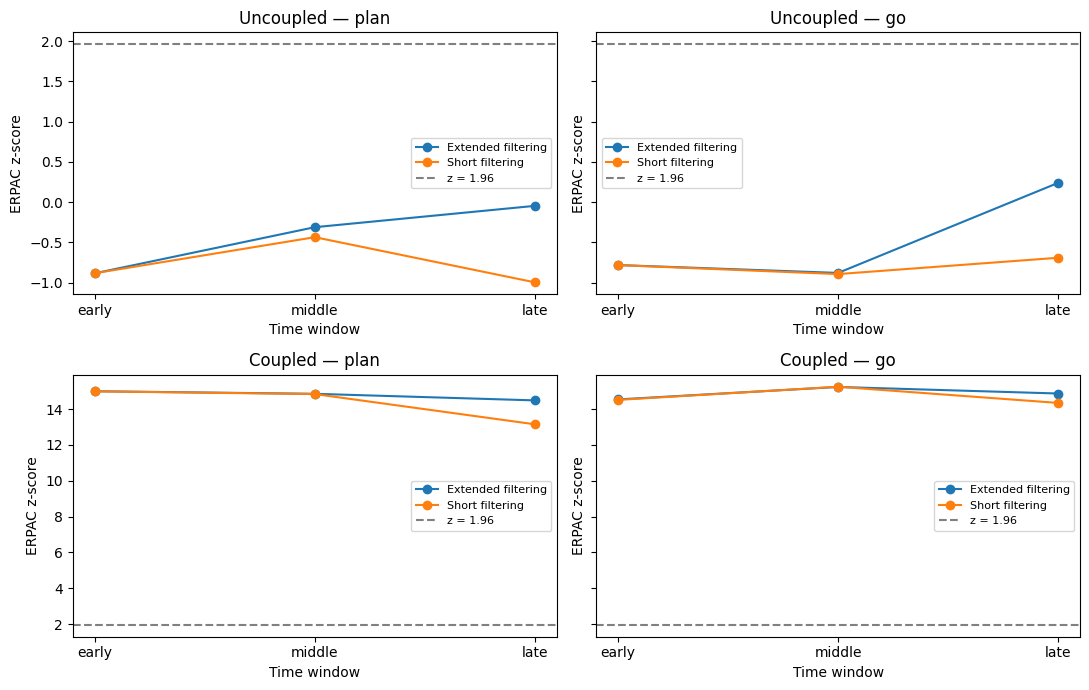

In [14]:
# Visualize z-normalized ERPAC
fig, axes = plt.subplots(
    2, 2,
    figsize=(11, 7),
    sharey="row"
)

for i, control in enumerate(
    ["Uncoupled", "Coupled"]
):

    for j, stage in enumerate(["plan", "go"]):

        ax = axes[i, j]

        d = z_comparison[
            (z_comparison["control"] == control)
            & (z_comparison["task_stage"] == stage)
        ]

        ax.plot(
            d["time_window"],
            d["Extended"],
            marker="o",
            label="Extended filtering"
        )

        ax.plot(
            d["time_window"],
            d["Short"],
            marker="o",
            label="Short filtering"
        )

        ax.axhline(
            1.96,
            color="grey",
            linestyle="--",
            label="z = 1.96"
        )

        ax.set_title(f"{control} — {stage}")
        ax.set_xlabel("Time window")
        ax.set_ylabel("ERPAC z-score")
        ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [15]:
# Evaluate different exclusion durations
exclusion_durations = [0, 50, 75, 100, 125, 150]

rows = []

for control in ["Uncoupled", "Coupled"]:

    extended = results[
        (control, "Extended")
    ]["observed_map"]

    short = results[
        (control, "Short")
    ]["observed_map"]

    for exclusion_ms in exclusion_durations:

        tmax = 0.5 - exclusion_ms / 1000

        mask = (
            (short_times >= 0)
            & (short_times < tmax)
        )

        extended_values = extended[..., mask]
        short_values = short[..., mask]

        extended_mean = extended_values.mean()
        short_mean = short_values.mean()

        # Relative difference in average ERPAC
        relative_diff = (
            (short_mean - extended_mean)
            / extended_mean * 100
        )

        # RMSE across the averaged ERPAC time courses
        extended_tc = extended_values.mean(axis=(0, 1))
        short_tc = short_values.mean(axis=(0, 1))

        rmse = np.sqrt(
            np.mean((short_tc - extended_tc)**2)
        )

        rows.append({
            "control": control,
            "excluded_ms": exclusion_ms,
            "analysis_end_ms": round(tmax * 1000),
            "extended_erpac": extended_mean,
            "short_erpac": short_mean,
            "relative_difference_pct": relative_diff,
            "rmse": rmse
        })

exclusion_comparison = pd.DataFrame(rows)

print(
    exclusion_comparison.round(6).to_string(index=False)
)

  control  excluded_ms  analysis_end_ms  extended_erpac  short_erpac  relative_difference_pct     rmse
Uncoupled            0              500        0.149214     0.143321                -3.949513 0.017062
Uncoupled           50              450        0.150674     0.145345                -3.536913 0.015838
Uncoupled           75              425        0.148907     0.146750                -1.448412 0.006988
Uncoupled          100              400        0.148764     0.147813                -0.639053 0.002906
Uncoupled          125              375        0.147512     0.146368                -0.775631 0.002904
Uncoupled          150              350        0.147030     0.146100                -0.632640 0.002659
  Coupled            0              500        0.508626     0.498076                -2.074216 0.023345
  Coupled           50              450        0.506298     0.500315                -1.181633 0.017031
  Coupled           75              425        0.505861     0.503059     

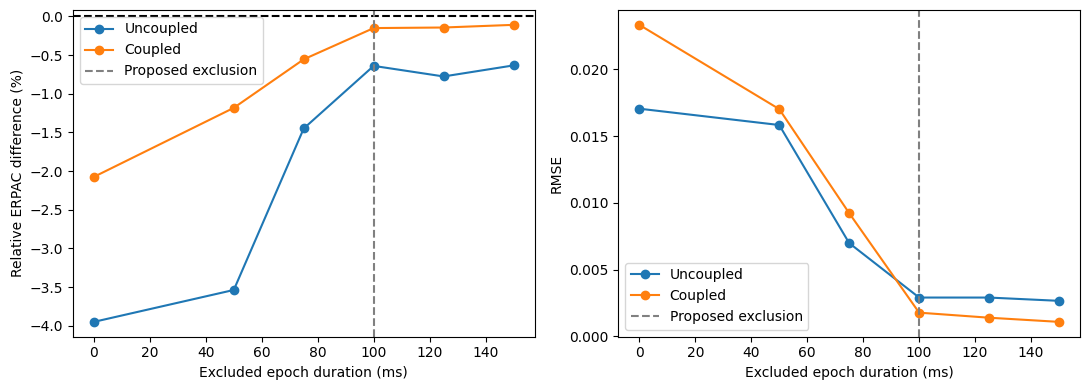

In [16]:
# Plot the results
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for control in ["Uncoupled", "Coupled"]:

    d = exclusion_comparison[
        exclusion_comparison["control"] == control
    ]

    axes[0].plot(
        d["excluded_ms"],
        d["relative_difference_pct"],
        marker="o",
        label=control
    )

    axes[1].plot(
        d["excluded_ms"],
        d["rmse"],
        marker="o",
        label=control
    )

axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_ylabel("Relative ERPAC difference (%)")
axes[1].set_ylabel("RMSE")

for ax in axes:

    ax.axvline(
        100,
        color="grey",
        linestyle="--",
        label="Proposed exclusion"
    )

    ax.set_xlabel("Excluded epoch duration (ms)")
    ax.legend()

plt.tight_layout()
plt.show()

# Sensitivity to coupling strength

In [19]:
MODULATION_DEPTHS = [
    0.0, 0.05, 0.10, 0.20,
    0.40, 0.60, 0.80
]

N_REPEATS = 20
VALIDATION_SEED = 2026

validation_windows = {
    "overall": (0.0, 0.4),
    "early": (0.0, 0.15),
    "middle": (0.15, 0.275),
    "late": (0.275, 0.4)
}

window_masks = {
    name: (
        (short_times >= tmin)
        & (short_times < tmax)
    )
    for name, (tmin, tmax)
    in validation_windows.items()
}

for name, mask in window_masks.items():
    print(name, mask.sum(), "samples")

def generate_base_signals(seed):

    rng = np.random.default_rng(seed)

    theta_offsets = rng.uniform(
        -np.pi, np.pi,
        size=(N_TRIALS, 1)
    )

    gamma_offsets = rng.uniform(
        -np.pi, np.pi,
        size=(N_TRIALS, 1)
    )

    theta_phase = (
        2 * np.pi * F_THETA * times[None, :]
        + theta_offsets
    )

    theta = np.sin(theta_phase)

    gamma = np.sin(
        2 * np.pi * F_GAMMA * times[None, :]
        + gamma_offsets
    )

    noise = rng.normal(
        0, 0.5,
        size=theta.shape
    )

    return theta_phase, theta, gamma, noise

def introduce_coupling(
    theta_phase,
    theta,
    gamma,
    noise,
    modulation_depth
):

    gamma_envelope = (
        1
        + modulation_depth * np.cos(theta_phase)
    )

    x = theta + gamma_envelope * gamma + noise

    return x

overall 200 samples
early 75 samples
middle 63 samples
late 62 samples


In [20]:
# ERPAC and surrogate normalization
def evaluate_coupling_strength(
    pha, amp, permutations
):

    observed_map = compute_erpac(pha, amp)

    observed_values = {
        name: observed_map[..., mask].mean()
        for name, mask in window_masks.items()
    }

    surrogate_values = {
        name: np.empty(len(permutations))
        for name in window_masks
    }

    for i, perm in enumerate(permutations):

        amp_shuffled = amp[:, perm, :]

        surrogate_map = compute_erpac(
            pha, amp_shuffled
        )

        for name, mask in window_masks.items():

            surrogate_values[name][i] = (
                surrogate_map[..., mask].mean()
            )

    rows = []

    for name in window_masks:

        observed = observed_values[name]
        sur = surrogate_values[name]

        sur_mean = sur.mean()
        sur_sd = sur.std(ddof=1)

        if not np.isfinite(sur_sd) or sur_sd <= 0:
            raise ValueError(
                f"Invalid surrogate SD: {name}"
            )

        z = (observed - sur_mean) / sur_sd

        p_empirical = (
            1 + np.sum(sur >= observed)
        ) / (len(sur) + 1)

        rows.append({
            "time_window": name,
            "observed": observed,
            "surrogate_mean": sur_mean,
            "surrogate_sd": sur_sd,
            "surrogate_skewness": skew(sur),
            "z": z,
            "p_empirical": p_empirical,
            "detected_z": z > 1.96,
            "detected_empirical": p_empirical < 0.05
        })

    return pd.DataFrame(rows)

# Run repeated simulations
from time import perf_counter

all_results = []

start = perf_counter()

for repeat in range(N_REPEATS):

    seed = VALIDATION_SEED + repeat

    # Generate independent synthetic signals
    base_signals = generate_base_signals(seed)

    # Same trial permutations across modulation depths
    rng_sur = np.random.default_rng(seed + 10000)

    permutations = np.stack([
        rng_sur.permutation(N_TRIALS)
        for _ in range(N_SURROGATES)
    ])

    for depth in MODULATION_DEPTHS:

        x = introduce_coupling(
            *base_signals,
            modulation_depth=depth
        )

        # Filter the original available 1 s epoch
        pha, amp = extract_phase_amplitude(
            x,
            extended=False
        )

        df = evaluate_coupling_strength(
            pha,
            amp,
            permutations
        )

        df["repeat"] = repeat + 1
        df["modulation_depth"] = depth

        all_results.append(df)

    print(
        f"Completed repeat {repeat + 1}/{N_REPEATS}"
        f" | Elapsed: {(perf_counter() - start)/60:.1f} min"
    )

strength_results = pd.concat(
    all_results,
    ignore_index=True
)

print("Validation completed.")
print(strength_results.shape)

# Summarise the results
strength_summary = (
    strength_results
    .groupby(
        ["modulation_depth", "time_window"],
        as_index=False
    )
    .agg(
        observed_mean=("observed", "mean"),
        observed_SD=("observed", "std"),

        surrogate_mean=("surrogate_mean", "mean"),
        surrogate_SD_mean=("surrogate_sd", "mean"),

        z_mean=("z", "mean"),
        z_SD=("z", "std"),

        mean_skewness=("surrogate_skewness", "mean"),

        detection_rate_z=("detected_z", "mean"),
        detection_rate_empirical=(
            "detected_empirical", "mean"
        ),

        n_repeats=("repeat", "nunique")
    )
)

strength_summary["detection_rate_z"] *= 100

strength_summary["detection_rate_empirical"] *= 100

overall_summary = strength_summary[
    strength_summary["time_window"] == "overall"
]

print(
    overall_summary.round(4).to_string(index=False)
)

Completed repeat 1/20 | Elapsed: 0.5 min
Completed repeat 2/20 | Elapsed: 1.0 min
Completed repeat 3/20 | Elapsed: 1.5 min
Completed repeat 4/20 | Elapsed: 2.0 min
Completed repeat 5/20 | Elapsed: 2.5 min
Completed repeat 6/20 | Elapsed: 3.0 min
Completed repeat 7/20 | Elapsed: 3.5 min
Completed repeat 8/20 | Elapsed: 4.2 min
Completed repeat 9/20 | Elapsed: 5.1 min
Completed repeat 10/20 | Elapsed: 6.0 min
Completed repeat 11/20 | Elapsed: 6.7 min
Completed repeat 12/20 | Elapsed: 7.2 min
Completed repeat 13/20 | Elapsed: 7.7 min
Completed repeat 14/20 | Elapsed: 8.2 min
Completed repeat 15/20 | Elapsed: 8.7 min
Completed repeat 16/20 | Elapsed: 9.2 min
Completed repeat 17/20 | Elapsed: 9.6 min
Completed repeat 18/20 | Elapsed: 10.1 min
Completed repeat 19/20 | Elapsed: 10.6 min
Completed repeat 20/20 | Elapsed: 11.0 min
Validation completed.
(560, 11)
 modulation_depth time_window  observed_mean  observed_SD  surrogate_mean  surrogate_SD_mean  z_mean   z_SD  mean_skewness  detection_

Plotting

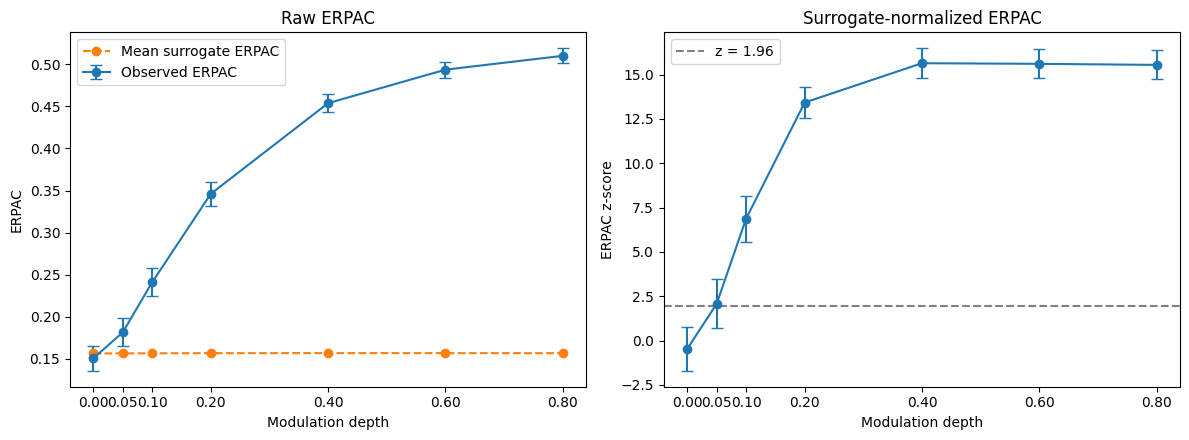

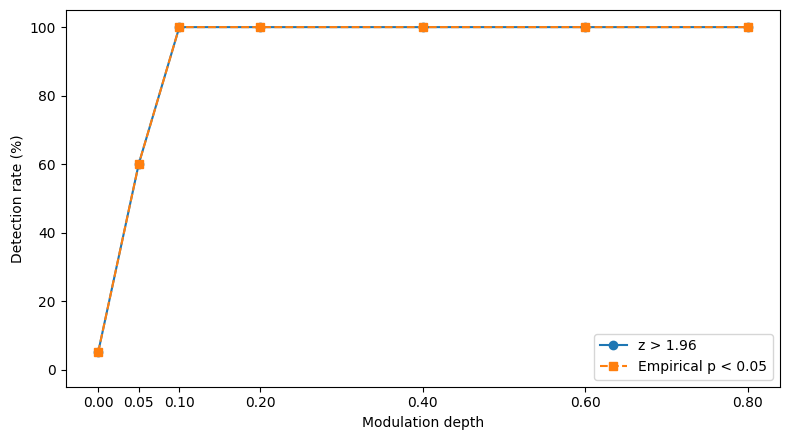

In [21]:
# Raw ERPAC and surrogate-normalized ERPAC
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.5)
)

d = overall_summary

# Raw ERPAC
axes[0].errorbar(
    d["modulation_depth"],
    d["observed_mean"],
    yerr=d["observed_SD"],
    marker="o",
    capsize=4,
    label="Observed ERPAC"
)

axes[0].plot(
    d["modulation_depth"],
    d["surrogate_mean"],
    marker="o",
    linestyle="--",
    label="Mean surrogate ERPAC"
)

axes[0].set_ylabel("ERPAC")
axes[0].set_title("Raw ERPAC")
axes[0].legend()

# Z-normalized ERPAC
axes[1].errorbar(
    d["modulation_depth"],
    d["z_mean"],
    yerr=d["z_SD"],
    marker="o",
    capsize=4
)

axes[1].axhline(
    1.96,
    color="grey",
    linestyle="--",
    label="z = 1.96"
)

axes[1].set_ylabel("ERPAC z-score")
axes[1].set_title("Surrogate-normalized ERPAC")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("Modulation depth")
    ax.set_xticks(MODULATION_DEPTHS)

plt.tight_layout()
plt.show()

# Coupling detection rates
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(
    d["modulation_depth"],
    d["detection_rate_z"],
    marker="o",
    label="z > 1.96"
)

ax.plot(
    d["modulation_depth"],
    d["detection_rate_empirical"],
    marker="s",
    linestyle="--",
    label="Empirical p < 0.05"
)

ax.set_xlabel("Modulation depth")
ax.set_ylabel("Detection rate (%)")

ax.set_ylim(-5, 105)
ax.set_xticks(MODULATION_DEPTHS)

ax.legend()

plt.tight_layout()
plt.show()

Compare the revised time windows

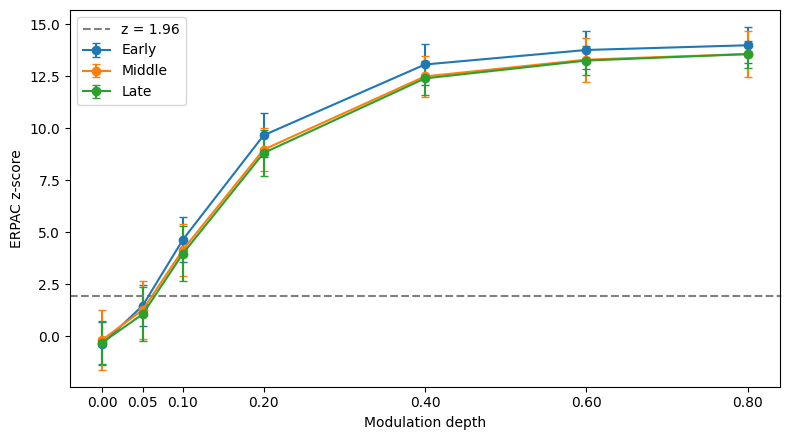

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.5))

for window in ["early", "middle", "late"]:

    d_window = strength_summary[
        strength_summary["time_window"] == window
    ]

    ax.errorbar(
        d_window["modulation_depth"],
        d_window["z_mean"],
        yerr=d_window["z_SD"],
        marker="o",
        capsize=3,
        label=window.capitalize()
    )

ax.axhline(
    1.96,
    color="grey",
    linestyle="--",
    label="z = 1.96"
)

ax.set_xlabel("Modulation depth")
ax.set_ylabel("ERPAC z-score")
ax.set_xticks(MODULATION_DEPTHS)

ax.legend()

plt.tight_layout()
plt.show()

Save validation results

In [23]:
from pathlib import Path

validation_dir = Path("validation_coupling_strength")

validation_dir.mkdir(
    parents=True, exist_ok=True
)

strength_results.to_csv(
    validation_dir / "strength_validation_full.csv",
    index=False
)

strength_summary.to_csv(
    validation_dir / "strength_validation_summary.csv",
    index=False
)

In [24]:
overall_summary

,modulation_depth,time_window,observed_mean,observed_SD,surrogate_mean,surrogate_SD_mean,z_mean,z_SD,mean_skewness,detection_rate_z,detection_rate_empirical,n_repeats
3,0.00,overall,0.150929,0.014782,0.156512,0.012052,-0.459001,1.232960,0.088701,5.0,5.0,20
7,0.05,overall,0.181666,0.016699,0.156605,0.012083,2.077050,1.371759,0.110678,60.0,60.0,20
11,0.10,overall,0.241042,0.016575,0.156704,0.012294,6.861521,1.308804,0.155136,100.0,100.0,20
15,0.20,overall,0.346097,0.014093,0.156856,0.014111,13.422674,0.895252,0.327284,100.0,100.0,20
19,0.40,overall,0.453819,0.010487,0.156944,0.019026,15.639830,0.833054,0.498977,100.0,100.0,20
23,0.60,overall,0.493599,0.009296,0.156910,0.021625,15.605527,0.816316,0.491846,100.0,100.0,20
27,0.80,overall,0.510047,0.008782,0.156863,0.022774,15.544820,0.815733,0.476738,100.0,100.0,20


# Sensitivity to trial counts validation

In [25]:
TRIAL_COUNTS = [
    20, 30, 40, 50, 66, 80, 100
]

TRIAL_MODULATION_DEPTHS = [
    0.0, 0.05, 0.10, 0.20
]

N_TRIAL_REPEATS = 20
MAX_TRIALS = max(TRIAL_COUNTS)

TRIAL_VALIDATION_SEED = 3026

def generate_base_signals_trials(seed, n_trials):

    rng = np.random.default_rng(seed)

    theta_offsets = rng.uniform(
        -np.pi, np.pi,
        size=(n_trials, 1)
    )

    gamma_offsets = rng.uniform(
        -np.pi, np.pi,
        size=(n_trials, 1)
    )

    theta_phase = (
        2 * np.pi * F_THETA * times[None, :]
        + theta_offsets
    )

    theta = np.sin(theta_phase)

    gamma = np.sin(
        2 * np.pi * F_GAMMA * times[None, :]
        + gamma_offsets
    )

    noise = rng.normal(
        0, 0.5,
        size=theta.shape
    )

    return theta_phase, theta, gamma, noise



In [26]:
from time import perf_counter

all_trial_results = []

start = perf_counter()

for repeat in range(N_TRIAL_REPEATS):

    seed = TRIAL_VALIDATION_SEED + repeat

    # Generate the maximum number of trials
    base_signals = generate_base_signals_trials(
        seed=seed,
        n_trials=MAX_TRIALS
    )

    # Randomized trial order for nested subsets
    rng_trials = np.random.default_rng(seed + 10000)

    trial_order = rng_trials.permutation(MAX_TRIALS)

    # Generate surrogate permutations for each trial count
    # Reuse them across modulation depths
    permutations_by_count = {}

    for n_trials in TRIAL_COUNTS:

        rng_sur = np.random.default_rng(
            seed + 20000 + n_trials
        )

        permutations_by_count[n_trials] = np.stack([
            rng_sur.permutation(n_trials)
            for _ in range(N_SURROGATES)
        ])

    for depth in TRIAL_MODULATION_DEPTHS:

        # Introduce coupling
        x = introduce_coupling(
            *base_signals,
            modulation_depth=depth
        )

        # Filter all 100 trials
        pha_full, amp_full = extract_phase_amplitude(
            x,
            extended=False
        )

        for n_trials in TRIAL_COUNTS:

            # Select a subset of trials
            indices = trial_order[:n_trials]

            pha = pha_full[:, indices, :]
            amp = amp_full[:, indices, :]

            # Retrieve matching surrogate permutations
            permutations = permutations_by_count[n_trials]

            # ERPAC and surrogate normalization
            df = evaluate_coupling_strength(
                pha,
                amp,
                permutations
            )

            df["repeat"] = repeat + 1
            df["modulation_depth"] = depth
            df["n_trials"] = n_trials

            all_trial_results.append(df)

    print(
        f"Completed repeat "
        f"{repeat + 1}/{N_TRIAL_REPEATS}"
        f" | Elapsed: "
        f"{(perf_counter() - start)/60:.1f} min"
    )

trial_results = pd.concat(
    all_trial_results,
    ignore_index=True
)

print("Validation completed.")
print(trial_results.shape)

trial_summary = (
    trial_results
    .groupby(
        [
            "n_trials",
            "modulation_depth",
            "time_window"
        ],
        as_index=False
    )
    .agg(
        observed_mean=("observed", "mean"),
        observed_SD=("observed", "std"),

        surrogate_mean=("surrogate_mean", "mean"),
        surrogate_SD_mean=("surrogate_sd", "mean"),

        z_mean=("z", "mean"),
        z_SD=("z", "std"),

        mean_skewness=("surrogate_skewness", "mean"),

        detection_rate_z=("detected_z", "mean"),

        detection_rate_empirical=(
            "detected_empirical", "mean"
        ),

        n_repeats=("repeat", "nunique")
    )
)

trial_summary["detection_rate_z"] *= 100

trial_summary["detection_rate_empirical"] *= 100

trial_overall = trial_summary[
    trial_summary["time_window"] == "overall"
].copy()

print(
    trial_overall.round(4).to_string(index=False)
)

Completed repeat 1/20 | Elapsed: 2.4 min
Completed repeat 2/20 | Elapsed: 4.7 min
Completed repeat 3/20 | Elapsed: 6.1 min
Completed repeat 4/20 | Elapsed: 8.8 min
Completed repeat 5/20 | Elapsed: 11.8 min
Completed repeat 6/20 | Elapsed: 14.7 min
Completed repeat 7/20 | Elapsed: 17.2 min
Completed repeat 8/20 | Elapsed: 18.6 min
Completed repeat 9/20 | Elapsed: 20.0 min
Completed repeat 10/20 | Elapsed: 21.4 min
Completed repeat 11/20 | Elapsed: 22.8 min
Completed repeat 12/20 | Elapsed: 24.2 min
Completed repeat 13/20 | Elapsed: 25.7 min
Completed repeat 14/20 | Elapsed: 27.1 min
Completed repeat 15/20 | Elapsed: 28.5 min
Completed repeat 16/20 | Elapsed: 29.9 min
Completed repeat 17/20 | Elapsed: 31.3 min
Completed repeat 18/20 | Elapsed: 32.7 min
Completed repeat 19/20 | Elapsed: 34.1 min
Completed repeat 20/20 | Elapsed: 35.5 min
Validation completed.
(2240, 12)
 n_trials  modulation_depth time_window  observed_mean  observed_SD  surrogate_mean  surrogate_SD_mean  z_mean   z_SD  m

Plotting

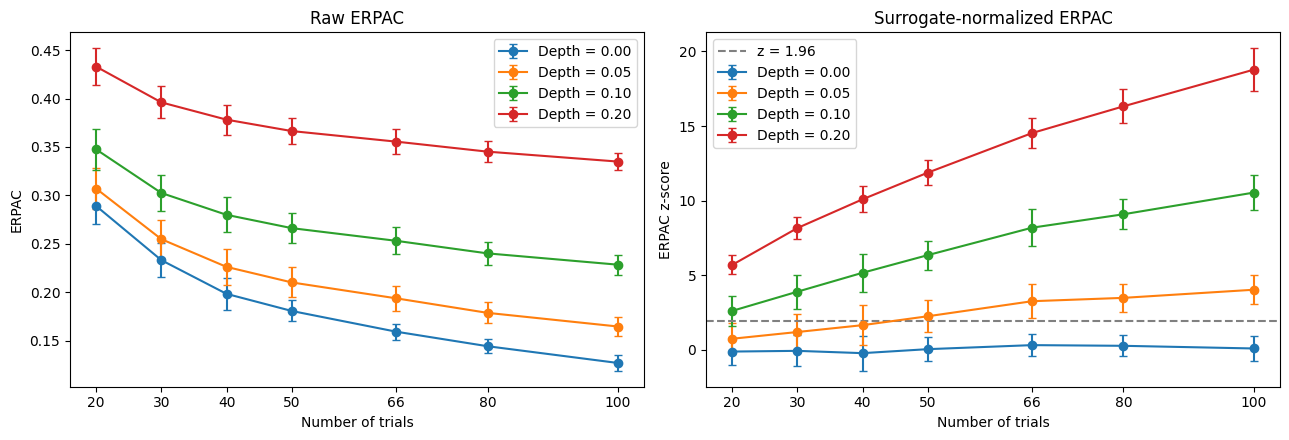

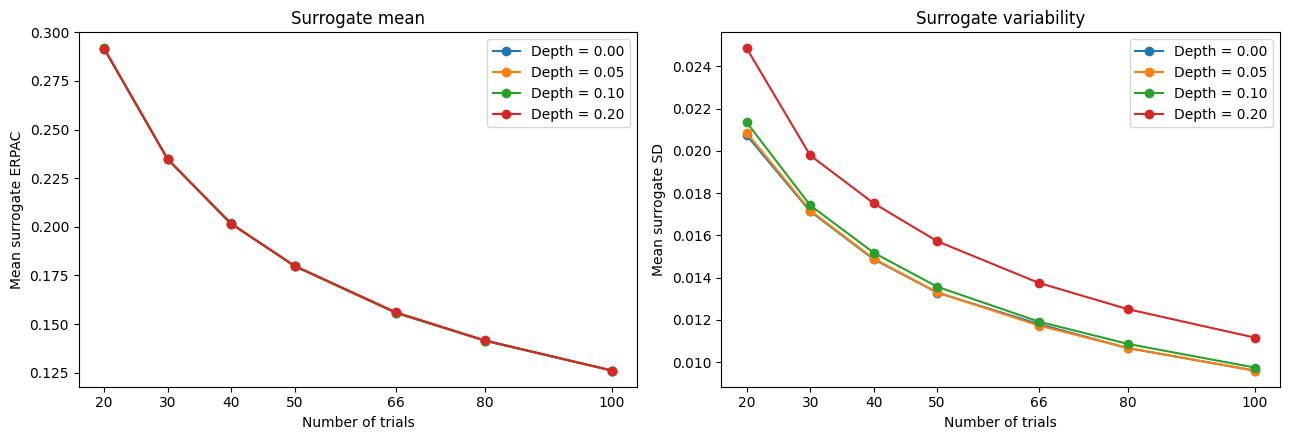

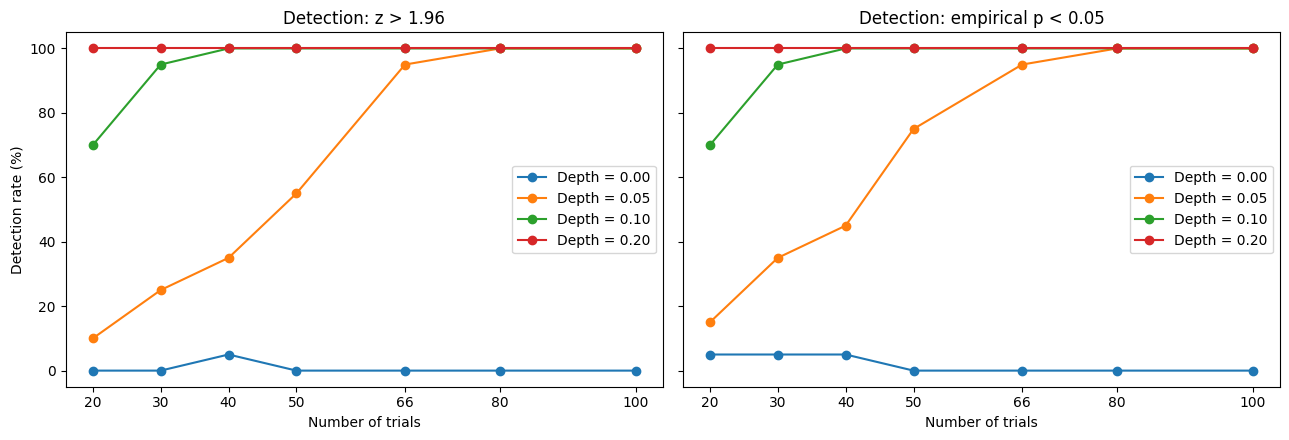

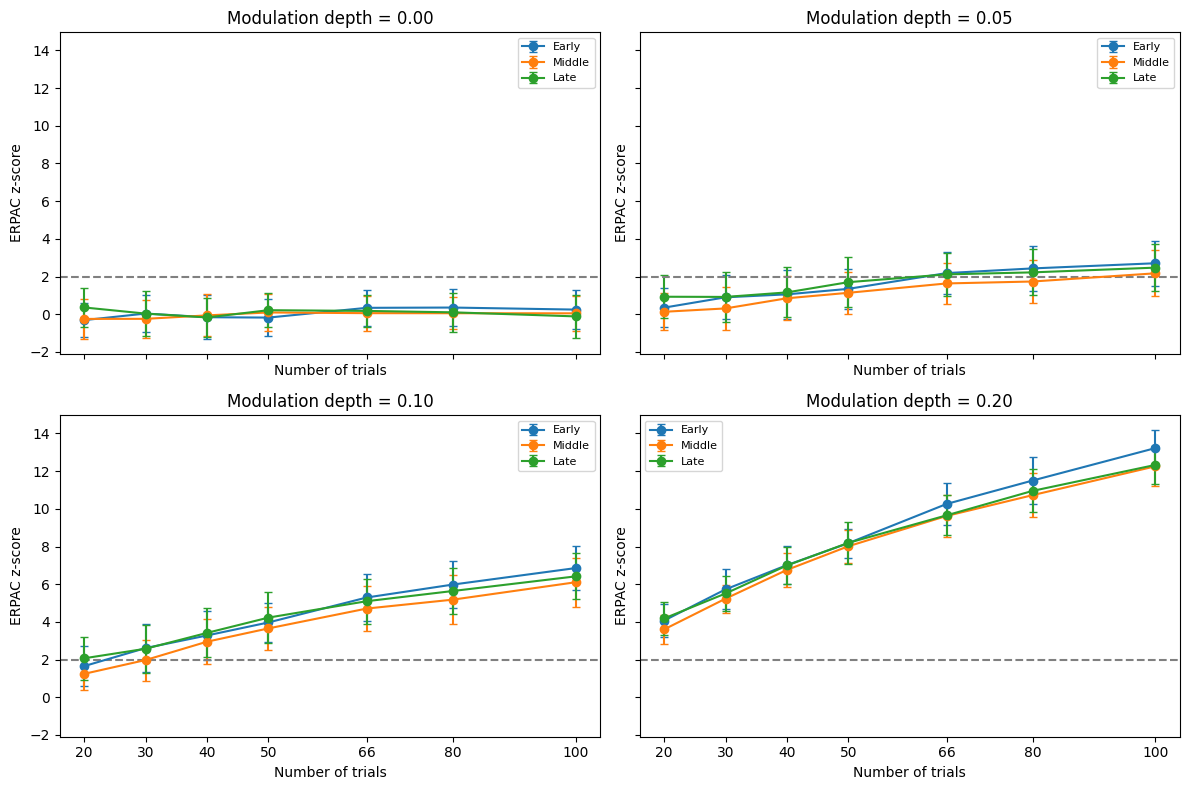

In [27]:
# Raw ERPAC and surrogate-normalized ERPAC
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4.5)
)

for depth in TRIAL_MODULATION_DEPTHS:

    d = trial_overall[
        trial_overall["modulation_depth"] == depth
    ]

    # Raw ERPAC
    axes[0].errorbar(
        d["n_trials"],
        d["observed_mean"],
        yerr=d["observed_SD"],
        marker="o",
        capsize=3,
        label=f"Depth = {depth:.2f}"
    )

    # Z-normalized ERPAC
    axes[1].errorbar(
        d["n_trials"],
        d["z_mean"],
        yerr=d["z_SD"],
        marker="o",
        capsize=3,
        label=f"Depth = {depth:.2f}"
    )

axes[0].set_title("Raw ERPAC")
axes[0].set_ylabel("ERPAC")

axes[1].axhline(
    1.96,
    color="grey",
    linestyle="--",
    label="z = 1.96"
)

axes[1].set_title("Surrogate-normalized ERPAC")
axes[1].set_ylabel("ERPAC z-score")

for ax in axes:

    ax.set_xlabel("Number of trials")
    ax.set_xticks(TRIAL_COUNTS)
    ax.legend()

plt.tight_layout()
plt.show()

# Surrogate distribution characteristics
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4.5)
)

for depth in TRIAL_MODULATION_DEPTHS:

    d = trial_overall[
        trial_overall["modulation_depth"] == depth
    ]

    axes[0].plot(
        d["n_trials"],
        d["surrogate_mean"],
        marker="o",
        label=f"Depth = {depth:.2f}"
    )

    axes[1].plot(
        d["n_trials"],
        d["surrogate_SD_mean"],
        marker="o",
        label=f"Depth = {depth:.2f}"
    )

axes[0].set_title("Surrogate mean")
axes[0].set_ylabel("Mean surrogate ERPAC")

axes[1].set_title("Surrogate variability")
axes[1].set_ylabel("Mean surrogate SD")

for ax in axes:

    ax.set_xlabel("Number of trials")
    ax.set_xticks(TRIAL_COUNTS)
    ax.legend()

plt.tight_layout()
plt.show()

# Coupling detection rates
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4.5),
    sharey=True
)

for depth in TRIAL_MODULATION_DEPTHS:

    d = trial_overall[
        trial_overall["modulation_depth"] == depth
    ]

    axes[0].plot(
        d["n_trials"],
        d["detection_rate_z"],
        marker="o",
        label=f"Depth = {depth:.2f}"
    )

    axes[1].plot(
        d["n_trials"],
        d["detection_rate_empirical"],
        marker="o",
        label=f"Depth = {depth:.2f}"
    )

axes[0].set_title("Detection: z > 1.96")
axes[1].set_title("Detection: empirical p < 0.05")

axes[0].set_ylabel("Detection rate (%)")

for ax in axes:

    ax.set_xlabel("Number of trials")
    ax.set_xticks(TRIAL_COUNTS)
    ax.set_ylim(-5, 105)
    ax.legend()

plt.tight_layout()
plt.show()

# Compare individual time windows
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8),
    sharex=True,
    sharey=True
)

for ax, depth in zip(
    axes.flat,
    TRIAL_MODULATION_DEPTHS
):

    for window in ["early", "middle", "late"]:

        d = trial_summary[
            (trial_summary["modulation_depth"] == depth)
            & (trial_summary["time_window"] == window)
        ]

        ax.errorbar(
            d["n_trials"],
            d["z_mean"],
            yerr=d["z_SD"],
            marker="o",
            capsize=3,
            label=window.capitalize()
        )

    ax.axhline(
        1.96,
        color="grey",
        linestyle="--"
    )

    ax.set_title(f"Modulation depth = {depth:.2f}")
    ax.set_xlabel("Number of trials")
    ax.set_ylabel("ERPAC z-score")
    ax.set_xticks(TRIAL_COUNTS)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [29]:
trial_overall

,n_trials,modulation_depth,time_window,observed_mean,observed_SD,surrogate_mean,surrogate_SD_mean,z_mean,z_SD,mean_skewness,detection_rate_z,detection_rate_empirical,n_repeats
3,20,0.00,overall,0.289119,0.018309,0.291657,0.020734,-0.104934,0.887903,0.113736,0.0,5.0,20
7,20,0.05,overall,0.307076,0.020993,0.291737,0.020852,0.751957,1.030903,0.123457,10.0,15.0,20
11,20,0.10,overall,0.347518,0.020915,0.291743,0.021347,2.616297,0.987149,0.136618,70.0,70.0,20
15,20,0.20,overall,0.432912,0.018755,0.291561,0.024849,5.694215,0.636804,0.260285,100.0,100.0,20
19,30,0.00,overall,0.233206,0.017389,0.234754,0.017135,-0.057279,1.041622,0.174250,0.0,5.0,20
23,30,0.05,overall,0.254855,0.019574,0.234743,0.017176,1.203913,1.198876,0.163250,25.0,35.0,20
27,30,0.10,overall,0.302517,0.018997,0.234743,0.017421,3.902676,1.134297,0.161469,95.0,95.0,20
31,30,0.20,overall,0.396002,0.016474,0.234746,0.019786,8.165314,0.725358,0.238178,100.0,100.0,20
35,40,0.00,overall,0.198421,0.016512,0.201712,0.014868,-0.211630,1.169539,0.181374,5.0,5.0,20
39,40,0.05,overall,0.226252,0.018948,0.201680,0.014897,1.662847,1.347857,0.185618,35.0,45.0,20


In [28]:
from pathlib import Path

validation_dir = Path("validation_trial_counts")

validation_dir.mkdir(
    parents=True,
    exist_ok=True
)

trial_results.to_csv(
    validation_dir / "trial_validation_full.csv",
    index=False
)

trial_summary.to_csv(
    validation_dir / "trial_validation_summary.csv",
    index=False
)